# M05-5（選讀）| weight_norm 在 PTQ：沒有 BN 能過，有 BN 要先拿掉

`torch.nn.utils.parametrize` 讓一個參數變成「由別的參數算出來」。`weight_norm` 就是一例：它把 `conv.weight` 換成
$g \cdot v / \lVert v \rVert$（$g$ 存在 `original0`、$v$ 存在 `original1`），每次存取 `conv.weight` 都重新計算。
不熟 parametrize 的話，先看官方的 [parametrize 教學](https://docs.pytorch.org/tutorials/intermediate/parametrizations.html)
與 [`weight_norm` 文件](https://docs.pytorch.org/docs/2.14/generated/torch.nn.utils.parametrizations.weight_norm.html)。

- **A.** export 之後：weight 變成圖上的一段計算。
- **B.** 沒有 BN：prepare、convert 都正常。
- **C.** 有 BN：`prepare_pt2e` 在折 BN 時報錯。
- **D.** 兩個解法：export 前在 module 上拿掉，或 export 後在圖上拿掉。

改圖的基本動作見 M00-4，BN 折疊見 M04-1。QAT 要在訓練期間保留 weight_norm，做法不同，見 M06-6。

In [1]:
import copy

import torch
from torch.nn.utils import parametrize

from common.data import calibration_batches
from common.graph_utils import op_counts
from common.models import ConvBnReLU, ConvReLU, example_inputs
from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.viz import draw, draw_stages, table
from common.weight_norm import add_weight_norm, strip_weight_norm

quiet()
_ = torch.manual_seed(0)


def make(cls, wrap=True):
    """小模型，BN 先暖過幾個 batch；wrap=True 時對 conv.weight 套用 weight_norm。"""
    torch.manual_seed(0)
    m = cls(3, 8).train()
    with torch.no_grad():
        for _ in range(3):
            m(torch.randn(16, 3, 16, 16))
    m.eval()
    if wrap:
        add_weight_norm(m)
    return m


def ptq(gm, **convert_kwargs):
    """prepare → 校準 128 筆 → convert，回傳 (prepared, converted)。"""
    prepared = prepare_pt2e(gm, get_xnnpack_quantizer(is_per_channel=True)[0])
    with torch.no_grad():
        for batch in calibration_batches(128):
            prepared(*batch)
    return prepared, convert_pt2e(copy.deepcopy(prepared), **convert_kwargs)


x = torch.randn(8, 3, 16, 16)

`add_weight_norm(model)` 是本專案的工具（`common/weight_norm.py`），等於對 `model.conv` 呼叫
`torch.nn.utils.parametrizations.weight_norm(model.conv, dim=0)`。

## A. export 之後：weight 變成一段計算

model 的參數： ['conv.bias', 'conv.parametrizations.weight.original0', 'conv.parametrizations.weight.original1']
套用 weight_norm 前後，eval 輸出 allclose： True （g 初始化成 ‖v‖，所以一開始值不變）


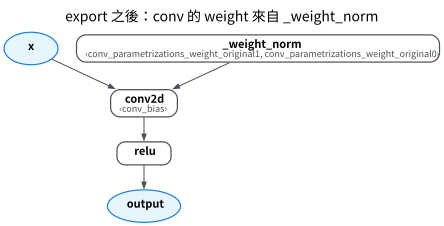

In [2]:
wn = make(ConvReLU)
with torch.no_grad():
    same = torch.allclose(make(ConvReLU, wrap=False)(x), wn(x), atol=1e-6)
print("model 的參數：", [n for n, _ in wn.named_parameters()])
print("套用 weight_norm 前後，eval 輸出 allclose：", same, "（g 初始化成 ‖v‖，所以一開始值不變）")
assert same

gm = export_module(copy.deepcopy(wn), example_inputs())
draw(gm, title="export 之後：conv 的 weight 來自 _weight_norm")

parametrize 把 `weight` 變成一個 property，export 只是追蹤 forward 的執行過程，所以 $g \cdot v / \lVert v \rVert$ 這段計算進了圖（`aten._weight_norm`）。
真正的參數是 `original0`（$g$）與 `original1`（$v$），寫在 `_weight_norm` 底下。
之後每個「對 weight 做事」的步驟，看到的都是這個 `call_function` node，不是 `get_attr`。

## B. 沒有 BN：prepare、convert 都正常

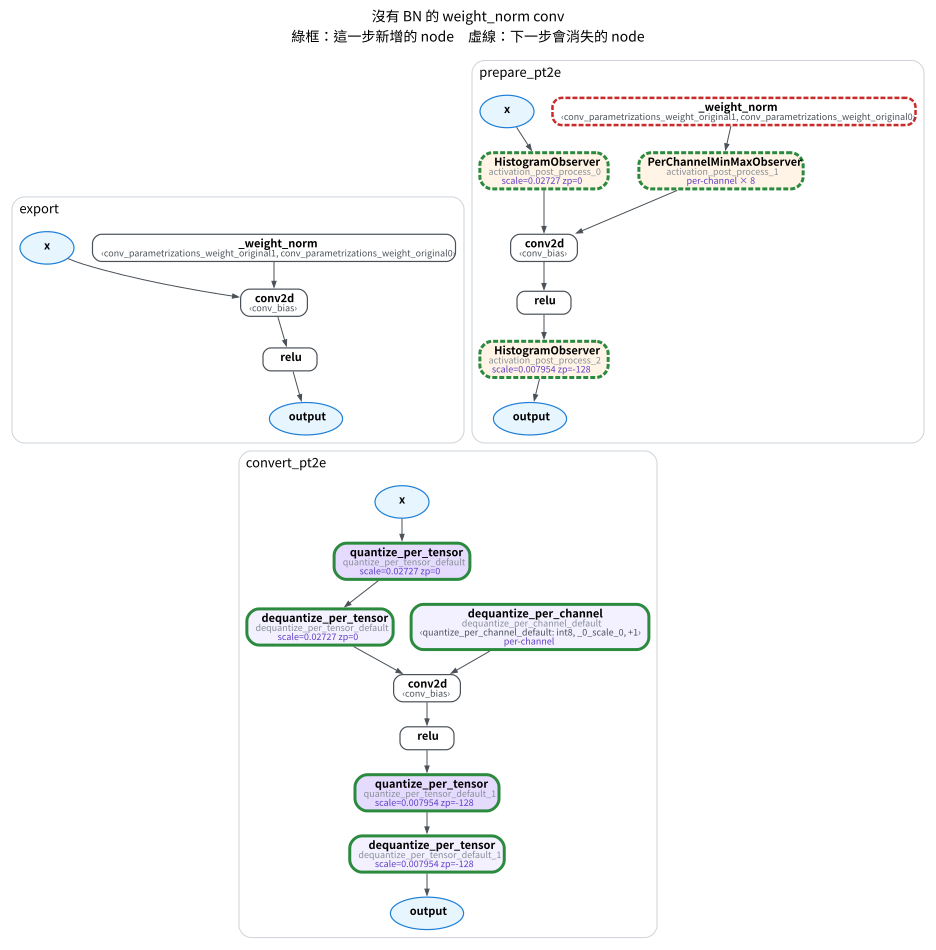

In [3]:
prepared, converted = ptq(copy.deepcopy(gm))
_, no_fold = ptq(copy.deepcopy(gm), fold_quantize=False)
draw_stages([(gm, "export"), (prepared, "prepare_pt2e"), (converted, "convert_pt2e")], title="沒有 BN 的 weight_norm conv")

In [4]:
rows = [["prepare_pt2e 之後", "_weight_norm" in op_counts(prepared)],
        ["convert_pt2e(prepared)", "_weight_norm" in op_counts(converted)],
        ["convert_pt2e(prepared, fold_quantize=False)", "_weight_norm" in op_counts(no_fold)]]
table(rows, ["哪一張圖", "還有 _weight_norm？"])

哪一張圖,還有 _weight_norm？
prepare_pt2e 之後,True
convert_pt2e(prepared),False
"convert_pt2e(prepared, fold_quantize=False)",True


In [5]:
assert [r[1] for r in rows] == [True, False, True]

- prepare 之後，weight 的 observer 掛在 `_weight_norm` 的輸出上：量化的是「算出來的 weight」，和一般的 conv 一樣。
- `convert_pt2e` 預設 `fold_quantize=True`，會把「輸入全是常數」的 quantize 預先算成 int8 常數（M02-3），`_weight_norm` 的輸入也全是常數，所以跟著 quantize 一起消失。`fold_quantize=False` 時兩者都留著。

## C. 有 BN：prepare_pt2e 在折 BN 時報錯

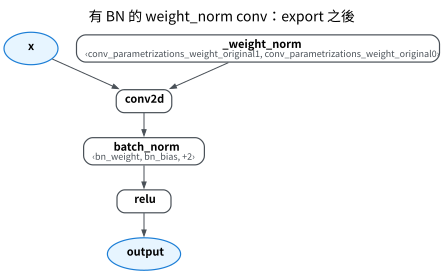

In [6]:
wn_bn = make(ConvBnReLU)
with torch.no_grad():
    y_wn_bn = wn_bn(x)
gm_bn = export_module(copy.deepcopy(wn_bn), example_inputs())
draw(gm_bn, title="有 BN 的 weight_norm conv：export 之後")

In [7]:
try:
    prepare_pt2e(copy.deepcopy(gm_bn), get_xnnpack_quantizer(is_per_channel=True)[0])
    error = None
except ValueError as e:
    error = e
print("prepare_pt2e →", f"{type(error).__name__}: {error}")
assert error is not None

prepare_pt2e → ValueError: Expected get_attr node, got call_function


PTQ 在 `prepare_pt2e` 一開始就折 BN（M04-1）：要把 conv 的 weight 當常數讀出來、乘上 BN 的係數再寫回去。
讀常數的是 torchao 內部函式 `_get_tensor_constant_from_node`，它只接受 `get_attr`（讀原始碼）。
weight 是 `_weight_norm` 這個 `call_function` 時，就直接報錯，不會默默跳過。

## D. 兩個解法

### 解法一：export 之前，在 module 上呼叫 `remove_parametrizations`

`leave_parametrized=True` 會把當下算出來的 weight 存成一般的參數，再拿掉 parametrization：

In [8]:
parametrize.remove_parametrizations(wn_bn.conv, "weight", leave_parametrized=True)
with torch.no_grad():
    same = torch.equal(wn_bn(x), y_wn_bn)
print("remove_parametrizations 之後的參數：", [n for n, _ in wn_bn.named_parameters()], "；輸出 torch.equal：", same)
assert same

remove_parametrizations 之後的參數： ['conv.weight', 'bn.weight', 'bn.bias'] ；輸出 torch.equal： True


這個解法有一個陷阱：deepcopy 出一份複本，只對**複本**拿掉 parametrization，原模型也跟著壞：

In [9]:
orig = make(ConvReLU)
clone = copy.deepcopy(orig)
parametrize.remove_parametrizations(clone.conv, "weight", leave_parametrized=True)
try:
    orig(x)
    trap = None
except AttributeError as e:
    trap = e
print("原模型 forward →", f"{type(trap).__name__}: {trap}")
assert trap is not None

原模型 forward → AttributeError: 'ParametrizedConv2d' object has no attribute 'weight'


parametrize 把 module 的 `__class__` 換成動態產生的 `ParametrizedConv2d`，deepcopy 不會複製類別，原模型和複本共用同一個類別。
對複本拿掉 parametrization 時，`weight` property 從共用的類別上被刪掉，原模型就找不到 `weight` 了。

### 解法二：export 之後，在圖上把 `_weight_norm` 換成常數

`strip_weight_norm(gm)` 是本專案的工具（`common/weight_norm.py`）：用圖上同一顆 `_weight_norm` 算出 weight，
存成新的參數、插一個 `get_attr` node，`replace_all_uses_with` 讓 conv 改吃它，再刪掉 `_weight_norm`（M00-4 的改圖動作）。

拔掉的 weight： ['conv.weight']
strip 前後輸出 torch.equal： True


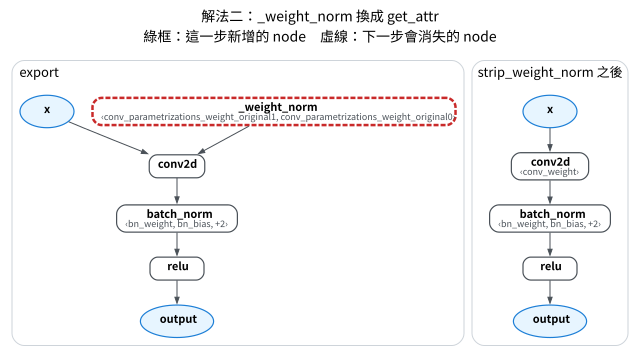

In [10]:
fixed = copy.deepcopy(gm_bn)
print("拔掉的 weight：", strip_weight_norm(fixed))
with torch.no_grad():
    same = torch.equal(fixed(x), gm_bn(x))
print("strip 前後輸出 torch.equal：", same)
assert same
draw_stages([(gm_bn, "export"), (fixed, "strip_weight_norm 之後")], title="解法二：_weight_norm 換成 get_attr")

In [11]:
_, c_fixed = ptq(fixed)
print("prepare_pt2e、convert_pt2e 都成功；convert 之後的 op：", dict(op_counts(c_fixed)))
assert "batch_norm" not in op_counts(c_fixed)

prepare_pt2e、convert_pt2e 都成功；convert 之後的 op： {'quantize_per_tensor': 2, 'dequantize_per_tensor': 2, 'dequantize_per_channel': 1, 'conv2d': 1, 'relu': 1}


解法二不碰 `nn.Module`：export 圖上的 conv 是普通的 module，$g$、$v$ 只是它底下的參數，改圖只動這張圖，不必擔心動態類別。
PTQ 不訓練，$g$、$v$ 本來就沒有用處，兩個解法都可以。

## 小結

- export 把 weight_norm 的計算追蹤進圖，conv 的 weight 變成 `aten._weight_norm`。
- 沒有 BN 時 PTQ 正常，convert 把它連同 quantize 折成常數；有 BN 時 `prepare_pt2e` 折 BN 要讀常數，直接報錯。
- PTQ 用不到 weight_norm：export 前用 `remove_parametrizations`（小心 deepcopy 的陷阱），或 export 後用 `strip_weight_norm`。
  QAT 要在訓練時保留 $g$、$v$，prepare 也不折 BN，做法見 M06-6。